# 09 Each Model Vs Two Baselines

Computes model skill relative to velocity persistence and spatial mean flow.

**Provenance.** This is an English-facing execution copy of the original project notebook. The computational cells are preserved so that the analysis remains reproducible. Chinese narrative cells have been replaced by concise English stage notes; the original notebook remains unchanged in the source project.

## Analysis stage 1

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'output/rq1/model_error_analysis').exists())
DATA=ROOT/'output/rq1/model_error_analysis'
OUT=DATA/'individual_baseline_comparisons';OUT.mkdir(exist_ok=True)
lead=pd.read_csv(DATA/'all_models_lead_metrics.csv')
summary=pd.read_csv(DATA/'model_error_summary_24_48_72.csv')
BASELINES=['Velocity persistence','Spatial mean flow']
MODELS=['FNN','Weighted KNN','Ridge','VAR(20)','VAR(1)']
COLORS={'Velocity persistence':'#606872','Spatial mean flow':'#A0A7AF','FNN':'#D81B60',
        'Weighted KNN':'#159D73','Ridge':'#2864DC','VAR(20)':'#7043A5','VAR(1)':'#E17C05'}

## Analysis stage 2

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

In [2]:
display(summary.set_index('Model').loc[MODELS+BASELINES].round(2))

,24h Median,24h RMSE,48h Median,48h RMSE,72h Median,72h RMSE,Median 72h ITE
Model,,,,,,,
FNN,11.32,18.15,26.10,40.21,41.72,62.15,1423.73
Weighted KNN,12.03,19.35,27.00,42.42,41.99,65.21,1462.93
Ridge,12.32,18.97,28.27,42.59,44.75,65.91,1531.79
VAR(20),12.32,19.17,27.52,42.81,44.25,66.07,1495.35
VAR(1),16.00,22.49,36.27,50.55,55.89,77.89,1894.78
Velocity persistence,16.47,24.07,36.54,55.17,61.35,90.10,1962.45
Spatial mean flow,21.69,29.87,39.96,57.27,56.42,80.98,2201.71


## Analysis stage 3

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

### FNN vs baselines

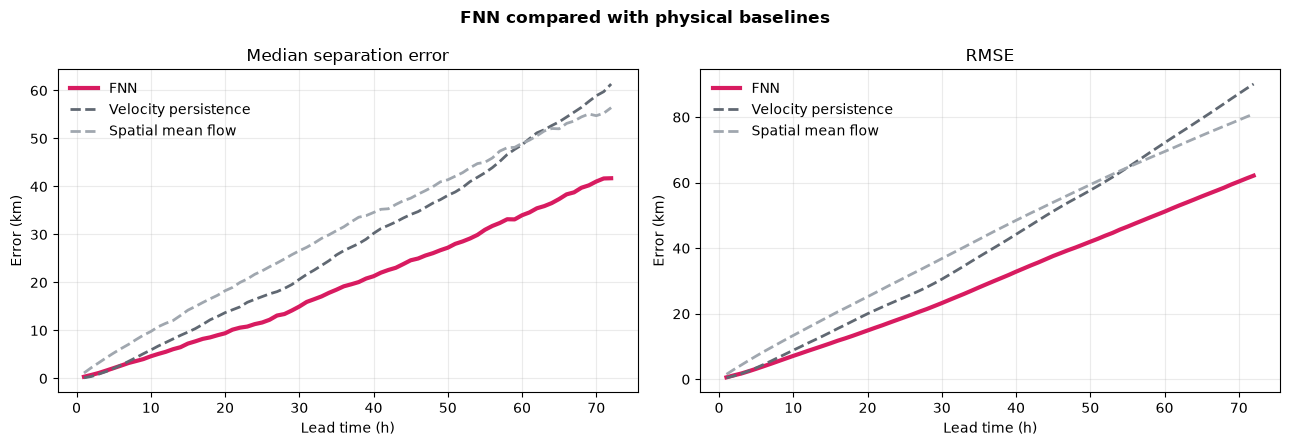

,Lead time,FNN Median,FNN RMSE,Persistence Median,Persistence RMSE,Mean flow Median,Mean flow RMSE,RMSE skill vs persistence (%),RMSE skill vs mean flow (%)
0,24 h,11.32,18.15,16.47,24.07,21.69,29.87,24.57,39.22
1,48 h,26.10,40.21,36.54,55.17,39.96,57.27,27.12,29.79
2,72 h,41.72,62.15,61.35,90.10,56.42,80.98,31.02,23.25


### Weighted KNN vs baselines

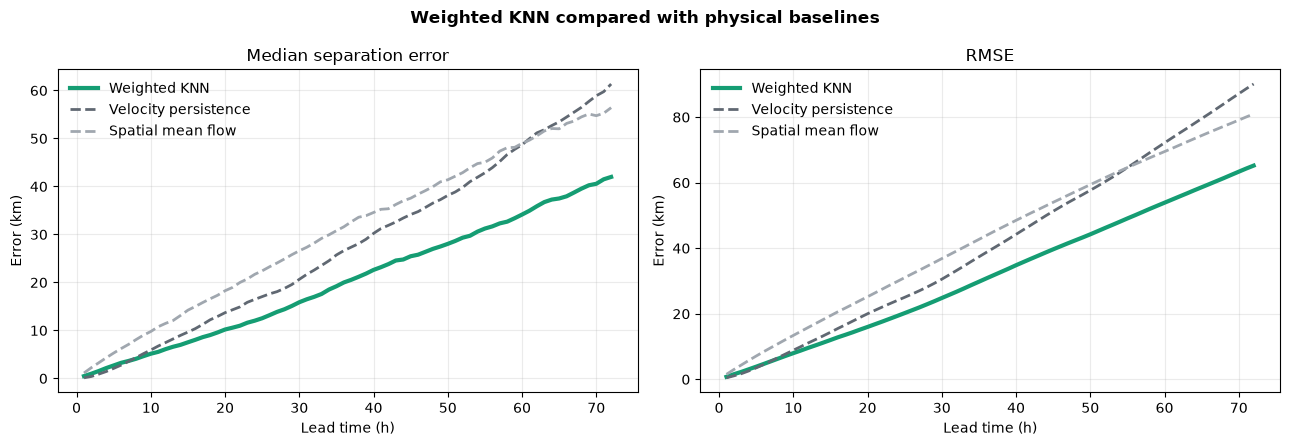

,Lead time,Weighted KNN Median,Weighted KNN RMSE,Persistence Median,Persistence RMSE,Mean flow Median,Mean flow RMSE,RMSE skill vs persistence (%),RMSE skill vs mean flow (%)
0,24 h,12.03,19.35,16.47,24.07,21.69,29.87,19.63,35.23
1,48 h,27.00,42.42,36.54,55.17,39.96,57.27,23.11,25.92
2,72 h,41.99,65.21,61.35,90.10,56.42,80.98,27.62,19.47


### Ridge vs baselines

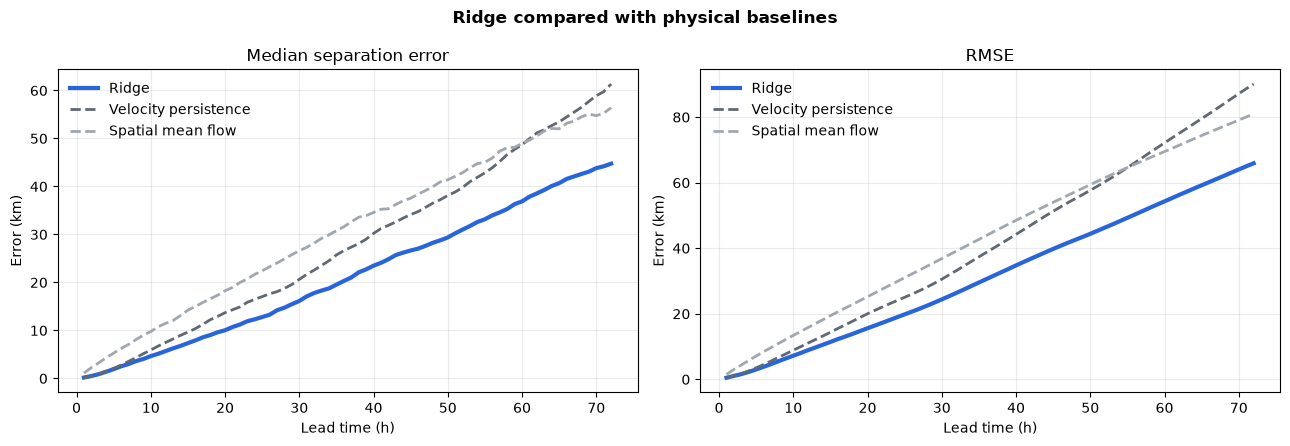

,Lead time,Ridge Median,Ridge RMSE,Persistence Median,Persistence RMSE,Mean flow Median,Mean flow RMSE,RMSE skill vs persistence (%),RMSE skill vs mean flow (%)
0,24 h,12.32,18.97,16.47,24.07,21.69,29.87,21.17,36.47
1,48 h,28.27,42.59,36.54,55.17,39.96,57.27,22.81,25.64
2,72 h,44.75,65.91,61.35,90.10,56.42,80.98,26.85,18.60


### VAR(20) vs baselines

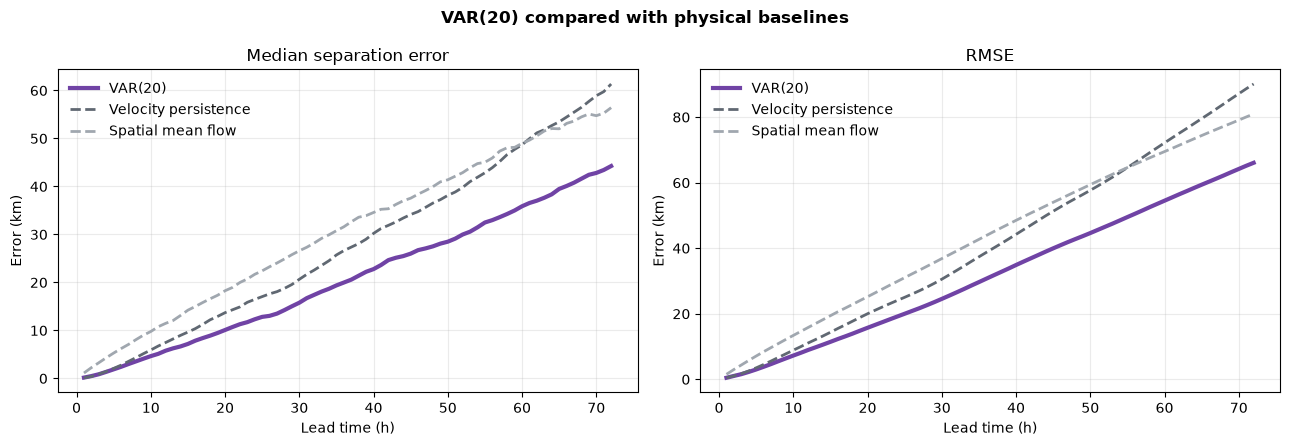

,Lead time,VAR(20) Median,VAR(20) RMSE,Persistence Median,Persistence RMSE,Mean flow Median,Mean flow RMSE,RMSE skill vs persistence (%),RMSE skill vs mean flow (%)
0,24 h,12.32,19.17,16.47,24.07,21.69,29.87,20.37,35.83
1,48 h,27.52,42.81,36.54,55.17,39.96,57.27,22.41,25.25
2,72 h,44.25,66.07,61.35,90.10,56.42,80.98,26.67,18.41


### VAR(1) vs baselines

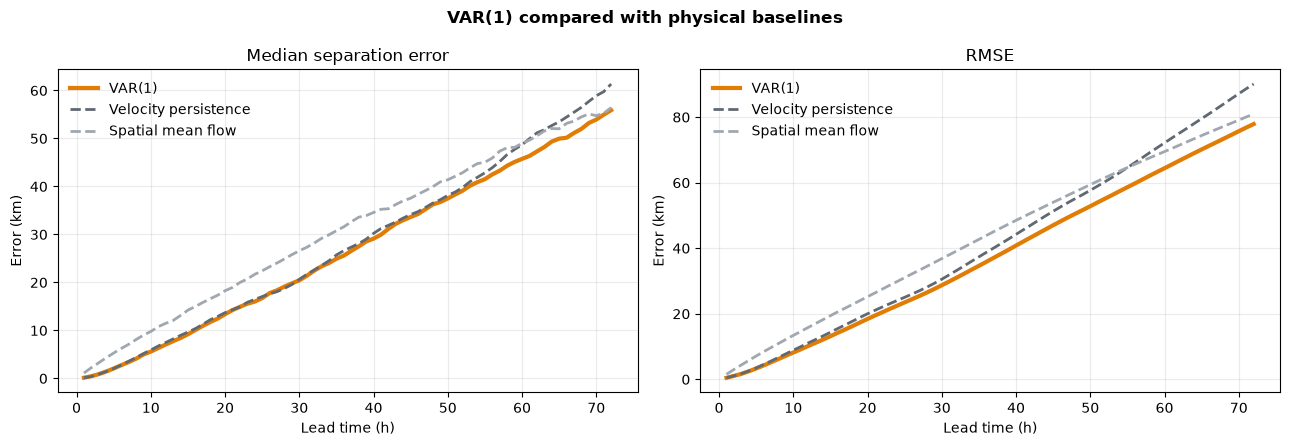

,Lead time,VAR(1) Median,VAR(1) RMSE,Persistence Median,Persistence RMSE,Mean flow Median,Mean flow RMSE,RMSE skill vs persistence (%),RMSE skill vs mean flow (%)
0,24 h,16.00,22.49,16.47,24.07,21.69,29.87,6.57,24.70
1,48 h,36.27,50.55,36.54,55.17,39.96,57.27,8.37,11.73
2,72 h,55.89,77.89,61.35,90.10,56.42,80.98,13.56,3.82


In [3]:
def model_table(model):
    rows=[]
    for h in [24,48,72]:
        values={}
        for name in [model]+BASELINES:
            r=lead[(lead.model.eq(name))&(lead.lead_time_hours.eq(h))].iloc[0]
            values[name]=(r.median_error_km,r.rmse_km)
        rows.append({'Lead time':f'{h} h',
          f'{model} Median':values[model][0],f'{model} RMSE':values[model][1],
          'Persistence Median':values[BASELINES[0]][0],'Persistence RMSE':values[BASELINES[0]][1],
          'Mean flow Median':values[BASELINES[1]][0],'Mean flow RMSE':values[BASELINES[1]][1],
          'RMSE skill vs persistence (%)':100*(1-values[model][1]/values[BASELINES[0]][1]),
          'RMSE skill vs mean flow (%)':100*(1-values[model][1]/values[BASELINES[1]][1])})
    return pd.DataFrame(rows)

for model in MODELS:
    display(Markdown(f'### {model} vs baselines'))
    fig,axes=plt.subplots(1,2,figsize=(13,4.5),sharex=True)
    for name in [model]+BASELINES:
        g=lead[lead.model.eq(name)].sort_values('lead_time_hours')
        style='-' if name==model else '--'; width=3 if name==model else 2
        axes[0].plot(g.lead_time_hours,g.median_error_km,label=name,color=COLORS[name],ls=style,lw=width)
        axes[1].plot(g.lead_time_hours,g.rmse_km,label=name,color=COLORS[name],ls=style,lw=width)
    axes[0].set_title('Median separation error');axes[1].set_title('RMSE')
    for ax in axes:
        ax.set(xlabel='Lead time (h)',ylabel='Error (km)');ax.grid(alpha=.25);ax.legend(frameon=False)
    fig.suptitle(f'{model} compared with physical baselines',fontweight='bold')
    fig.tight_layout();fig.savefig(OUT/f"{model.lower().replace(' ','_').replace('(','').replace(')','')}_vs_baselines.png",dpi=200,bbox_inches='tight')
    plt.show()
    table=model_table(model)
    display(table.round(2))
    table.to_csv(OUT/f"{model.lower().replace(' ','_').replace('(','').replace(')','')}_vs_baselines.csv",index=False)

## Analysis stage 4

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

,vs Velocity persistence (%),vs Spatial mean flow (%)
Model,,
FNN,31.02,23.25
Weighted KNN,27.62,19.47
Ridge,26.85,18.60
VAR(20),26.67,18.41
VAR(1),13.56,3.82


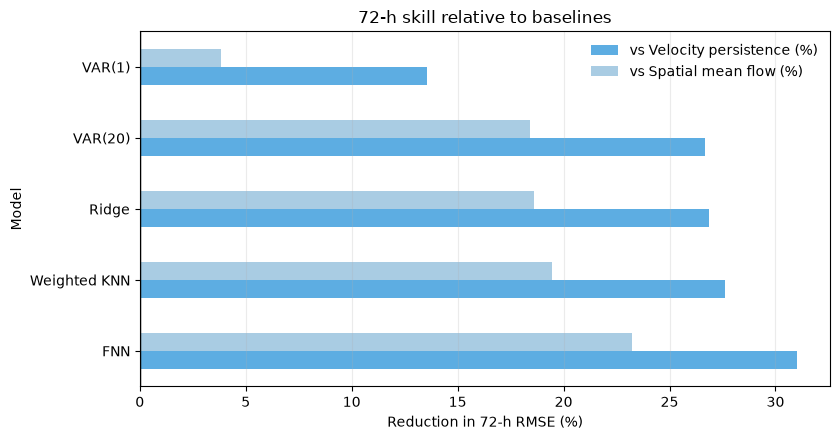

In [4]:
skill=[]
for model in MODELS:
    t=model_table(model).iloc[-1]
    skill.append({'Model':model,'vs Velocity persistence (%)':t['RMSE skill vs persistence (%)'],
                  'vs Spatial mean flow (%)':t['RMSE skill vs mean flow (%)']})
skill=pd.DataFrame(skill).set_index('Model')
display(skill.round(2))
ax=skill.plot.barh(figsize=(8.5,4.5),color=['#5DADE2','#A9CCE3'])
ax.axvline(0,color='black',lw=1);ax.set(xlabel='Reduction in 72-h RMSE (%)',title='72-h skill relative to baselines')
ax.grid(axis='x',alpha=.25);ax.legend(frameon=False)
plt.tight_layout();plt.savefig(OUT/'all_models_72h_skill.png',dpi=200,bbox_inches='tight');plt.show()
skill.to_csv(OUT/'all_models_72h_skill.csv')